In [ ]:
#My source is Open metio
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 25.5941,
    "longitude": 85.1376,
    "start_date": "2015-01-01",
    "end_date": "2024-12-31",

    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "precipitation,"
        "pressure_msl,"
        "wind_speed_10m"
    ),

    "timezone": "Asia/Kolkata"
}

# Send request to Open-Meteo
response = requests.get(url, params=params)

# Convert response to Python dictionary
data = response.json()

# Convert hourly data into a DataFrame
df = pd.DataFrame(data["hourly"])

# Save as CSV
df.to_csv("weather_2015_2024.csv", index=False)

print("Download complete!")
print(df.head())
print("Number of rows:", len(df))

Download complete!
               time  temperature_2m  relative_humidity_2m  precipitation  \
0  2015-01-01T00:00            14.9                    90            0.0   
1  2015-01-01T01:00            15.0                    90            0.0   
2  2015-01-01T02:00            14.6                    91            0.0   
3  2015-01-01T03:00            14.1                    93            0.0   
4  2015-01-01T04:00            13.9                    93            0.0   

   pressure_msl  wind_speed_10m  
0        1015.5             7.5  
1        1015.0             8.3  
2        1014.7             6.4  
3        1014.5             6.5  
4        1014.7             7.0  
Number of rows: 87672


# Welcome to Colab!

In [ ]:
from google.colab import files
uploaded = files.upload()
import pandas as pd
df = pd.read_csv("Weather_data_2015 to 2024.csv")
df.head()

Saving Weather_data_2015 to 2024.csv to Weather_data_2015 to 2024 (1).csv


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m
0,2015-01-01 00:00:00,14.9,90,0.0,1015.5,7.5
1,2015-01-01 01:00:00,15.0,90,0.0,1015.0,8.3
2,2015-01-01 02:00:00,14.6,91,0.0,1014.7,6.4
3,2015-01-01 03:00:00,14.1,93,0.0,1014.5,6.5
4,2015-01-01 04:00:00,13.9,93,0.0,1014.7,7.0


In [ ]:
import pandas as pd
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (87672, 6)

Columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'pressure_msl', 'wind_speed_10m']

First 5 rows:


,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m
0,2015-01-01 00:00:00,14.9,90,0.0,1015.5,7.5
1,2015-01-01 01:00:00,15.0,90,0.0,1015.0,8.3
2,2015-01-01 02:00:00,14.6,91,0.0,1014.7,6.4
3,2015-01-01 03:00:00,14.1,93,0.0,1014.5,6.5
4,2015-01-01 04:00:00,13.9,93,0.0,1014.7,7.0


In [ ]:
#here we use this to check the missing data
print(df.isnull().sum())

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
dtype: int64


In [ ]:
print(df.dtypes)

time                     object
temperature_2m          float64
relative_humidity_2m      int64
precipitation           float64
pressure_msl            float64
wind_speed_10m          float64
dtype: object


In [ ]:
df["time"] = pd.to_datetime(df["time"])
print(df.dtypes)

time                    datetime64[ns]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
pressure_msl                   float64
wind_speed_10m                 float64
dtype: object


In [ ]:
#data range and total observatins
print("Start date:", df["time"].min())
print("End date:", df["time"].max())
print("Total observations:", len(df))

Start date: 2015-01-01 00:00:00
End date: 2024-12-31 23:00:00
Total observations: 87672


In [ ]:
#Start
df = df.sort_values("time").reset_index(drop=True)

In [ ]:
df["hour"] = df["time"].dt.hour
df["day"] = df["time"].dt.day
df["month"] = df["time"].dt.month
df["day_of_year"] = df["time"].dt.dayofyear
df["year"] = df["time"].dt.year

In [ ]:
display(df.head())

,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,hour,day,month,day_of_year,year
0,2015-01-01 00:00:00,14.9,90,0.0,1015.5,7.5,0,1,1,1,2015
1,2015-01-01 01:00:00,15.0,90,0.0,1015.0,8.3,1,1,1,1,2015
2,2015-01-01 02:00:00,14.6,91,0.0,1014.7,6.4,2,1,1,1,2015
3,2015-01-01 03:00:00,14.1,93,0.0,1014.5,6.5,3,1,1,1,2015
4,2015-01-01 04:00:00,13.9,93,0.0,1014.7,7.0,4,1,1,1,2015


In [ ]:
df["target_temperature"] = df["temperature_2m"].shift(-24)

In [ ]:
# Temperature from previous hours
df["temp_lag_1"] = df["temperature_2m"].shift(1)
df["temp_lag_3"] = df["temperature_2m"].shift(3)
df["temp_lag_6"] = df["temperature_2m"].shift(6)
df["temp_lag_12"] = df["temperature_2m"].shift(12)
df["temp_lag_24"] = df["temperature_2m"].shift(24)

# Other weather variables from 24 hours ago
df["humidity_lag_24"] = df["relative_humidity_2m"].shift(24)
df["precip_lag_24"] = df["precipitation"].shift(24)
df["pressure_lag_24"] = df["pressure_msl"].shift(24)
df["wind_lag_24"] = df["wind_speed_10m"].shift(24)

In [ ]:
df["target_temperature"] = df["temperature_2m"].shift(-24)

In [ ]:
df = df.dropna().reset_index(drop=True)

In [ ]:
print(df.shape)
print(df.isnull().sum())

(87624, 21)
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
hour                    0
day                     0
month                   0
day_of_year             0
year                    0
target_temperature      0
temp_lag_1              0
temp_lag_3              0
temp_lag_6              0
temp_lag_12             0
temp_lag_24             0
humidity_lag_24         0
precip_lag_24           0
pressure_lag_24         0
wind_lag_24             0
dtype: int64


In [ ]:
display(df.head())

,time,temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m,hour,day,month,day_of_year,...,target_temperature,temp_lag_1,temp_lag_3,temp_lag_6,temp_lag_12,temp_lag_24,humidity_lag_24,precip_lag_24,pressure_lag_24,wind_lag_24
0,2015-01-02 00:00:00,19.5,75,0.0,1015.5,9.3,0,2,1,2,...,19.6,20.2,20.2,21.2,23.8,14.9,90.0,0.0,1015.5,7.5
1,2015-01-02 01:00:00,19.5,76,0.0,1015.3,9.5,1,2,1,2,...,19.4,19.5,20.3,20.6,24.5,15.0,90.0,0.0,1015.0,8.3
2,2015-01-02 02:00:00,19.2,78,0.0,1014.9,9.0,2,2,1,2,...,19.2,19.5,20.2,20.4,24.8,14.6,91.0,0.0,1014.7,6.4
3,2015-01-02 03:00:00,18.7,81,0.0,1015.2,8.3,3,2,1,2,...,19.0,19.2,19.5,20.2,24.7,14.1,93.0,0.0,1014.5,6.5
4,2015-01-02 04:00:00,18.5,83,0.0,1014.9,7.7,4,2,1,2,...,19.1,18.7,19.5,20.3,23.7,13.9,93.0,0.0,1014.7,7.0


In [ ]:
train = df[df["time"] < "2024-01-01"].copy()
test = df[df["time"] >= "2024-01-01"].copy()

print("Training data:", train.shape)
print("Testing data:", test.shape)

print("Training period:", train["time"].min(), "→", train["time"].max())
print("Testing period:", test["time"].min(), "→", test["time"].max())

Training data: (78864, 21)
Testing data: (8760, 21)
Training period: 2015-01-02 00:00:00 → 2023-12-31 23:00:00
Testing period: 2024-01-01 00:00:00 → 2024-12-30 23:00:00


In [ ]:
features = [
    "hour",
    "day",
    "month",
    "day_of_year",
    "temp_lag_1",
    "temp_lag_3",
    "temp_lag_6",
    "temp_lag_12",
    "temp_lag_24",
    "humidity_lag_24",
    "precip_lag_24",
    "pressure_lag_24",
    "wind_lag_24"
]

target = "target_temperature"

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
predictions = model.predict(X_test)

print(predictions[:10])

[11.525 11.432 11.576 10.946 10.651 10.115  9.663 11.186 12.997 13.939]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 1.1275744292237442
RMSE: 1.5102734310480603


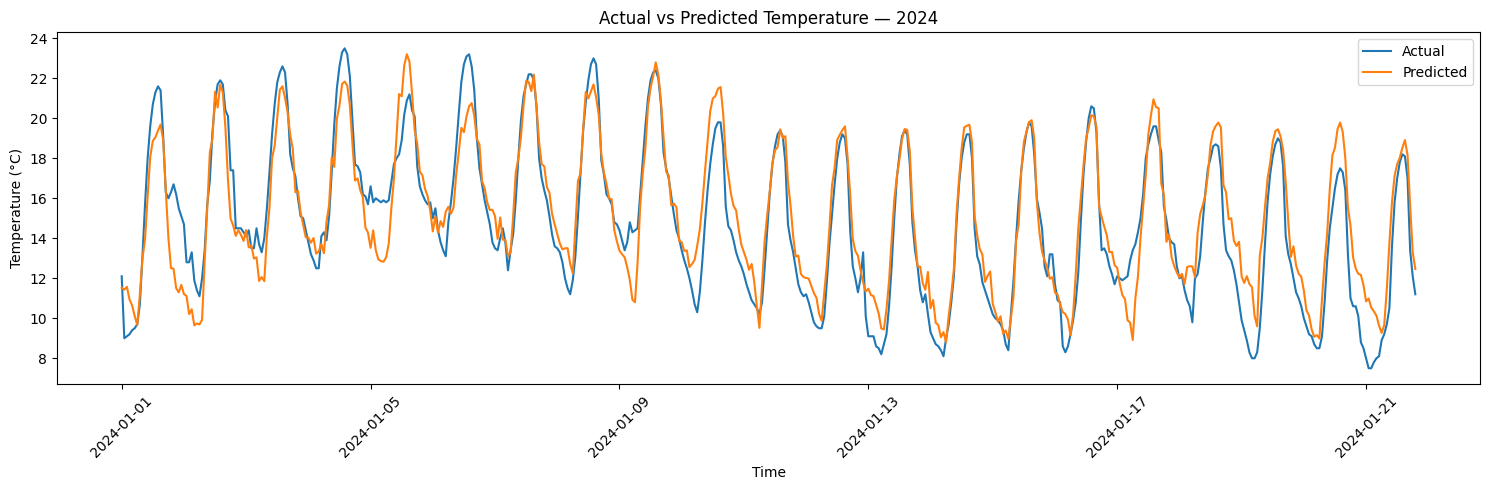

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    test["time"].iloc[:500],
    y_test.iloc[:500],
    label="Actual"
)

plt.plot(
    test["time"].iloc[:500],
    predictions[:500],
    label="Predicted"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs Predicted Temperature — 2024")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# More temperature history
df["temp_lag_48"] = df["temperature_2m"].shift(48)
df["temp_lag_72"] = df["temperature_2m"].shift(72)
df["temp_lag_168"] = df["temperature_2m"].shift(168)

# More humidity history
df["humidity_lag_48"] = df["relative_humidity_2m"].shift(48)
df["humidity_lag_168"] = df["relative_humidity_2m"].shift(168)

# More pressure history
df["pressure_lag_48"] = df["pressure_msl"].shift(48)
df["pressure_lag_168"] = df["pressure_msl"].shift(168)

In [ ]:
features = [
    "hour",
    "day",
    "month",
    "day_of_year",

    "temp_lag_1",
    "temp_lag_3",
    "temp_lag_6",
    "temp_lag_12",
    "temp_lag_24",
    "temp_lag_48",
    "temp_lag_72",
    "temp_lag_168",

    "humidity_lag_24",
    "humidity_lag_48",
    "humidity_lag_168",

    "precip_lag_24",

    "pressure_lag_24",
    "pressure_lag_48",
    "pressure_lag_168",

    "wind_lag_24"
]

In [ ]:
df = df.dropna().reset_index(drop=True)

train = df[df["time"] < "2024-01-01"].copy()
test = df[df["time"] >= "2024-01-01"].copy()

X_train = train[features]
y_train = train["target_temperature"]

X_test = test[features]
y_test = test["target_temperature"]

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model2 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model2.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
predictions2 = model2.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae2 = mean_absolute_error(y_test, predictions2)
rmse2 = np.sqrt(mean_squared_error(y_test, predictions2))

print("Improved MAE:", mae2)
print("Improved RMSE:", rmse2)

Improved MAE: 1.1163073630136984
Improved RMSE: 1.4915636089402424


In [ ]:
print("Old MAE:", 1.1275744292237442)
print("New MAE:", mae2)

print("Old RMSE:", 1.5102734310480603)
print("New RMSE:", rmse2)

Old MAE: 1.1275744292237442
New MAE: 1.1163073630136984
Old RMSE: 1.5102734310480603
New RMSE: 1.4915636089402424


In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
xgb_predictions = xgb_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)

XGBoost MAE: 1.10856120751873
XGBoost RMSE: 1.4772260715204586


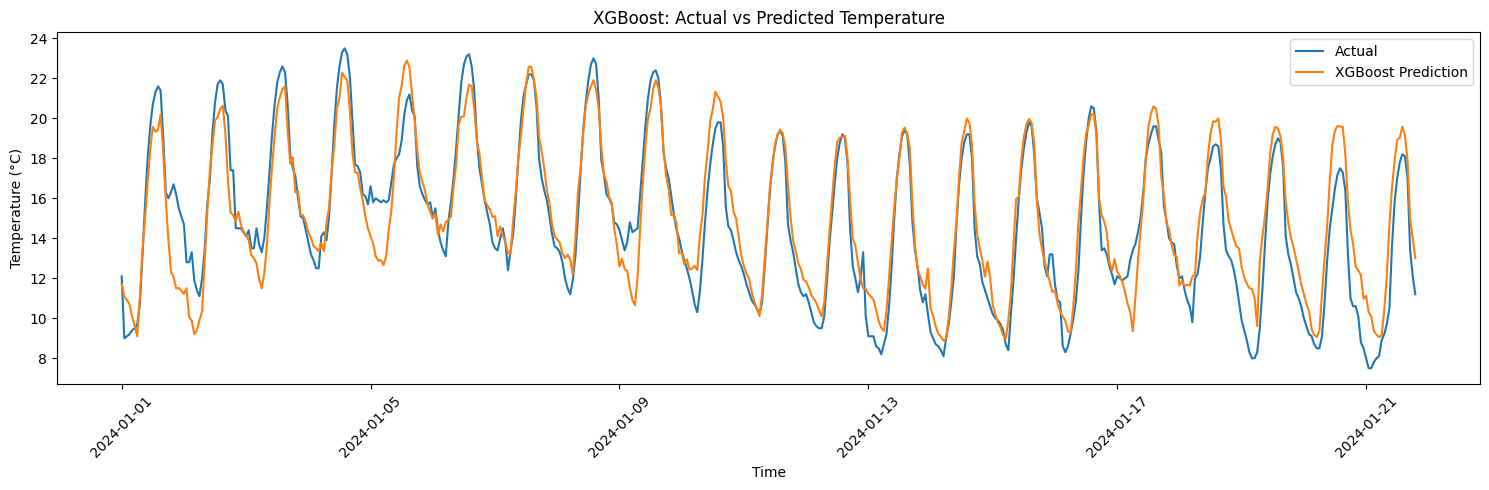

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    test["time"].iloc[:500],
    y_test.iloc[:500],
    label="Actual"
)

plt.plot(
    test["time"].iloc[:500],
    xgb_predictions[:500],
    label="XGBoost Prediction"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("XGBoost: Actual vs Predicted Temperature")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

temp_lag_1          0.496472
temp_lag_24         0.415079
temp_lag_48         0.027347
temp_lag_168        0.011787
temp_lag_72         0.008697
hour                0.007180
temp_lag_3          0.004924
month               0.004002
temp_lag_6          0.003901
day_of_year         0.003868
humidity_lag_168    0.002167
humidity_lag_48     0.002138
temp_lag_12         0.001884
wind_lag_24         0.001746
pressure_lag_48     0.001696
humidity_lag_24     0.001583
pressure_lag_168    0.001548
pressure_lag_24     0.001481
day                 0.001453
precip_lag_24       0.001047
dtype: float32


In [ ]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

temp_lag_1          0.496472
temp_lag_24         0.415079
temp_lag_48         0.027347
temp_lag_168        0.011787
temp_lag_72         0.008697
hour                0.007180
temp_lag_3          0.004924
month               0.004002
temp_lag_6          0.003901
day_of_year         0.003868
humidity_lag_168    0.002167
humidity_lag_48     0.002138
temp_lag_12         0.001884
wind_lag_24         0.001746
pressure_lag_48     0.001696
humidity_lag_24     0.001583
pressure_lag_168    0.001548
pressure_lag_24     0.001481
day                 0.001453
precip_lag_24       0.001047
dtype: float32


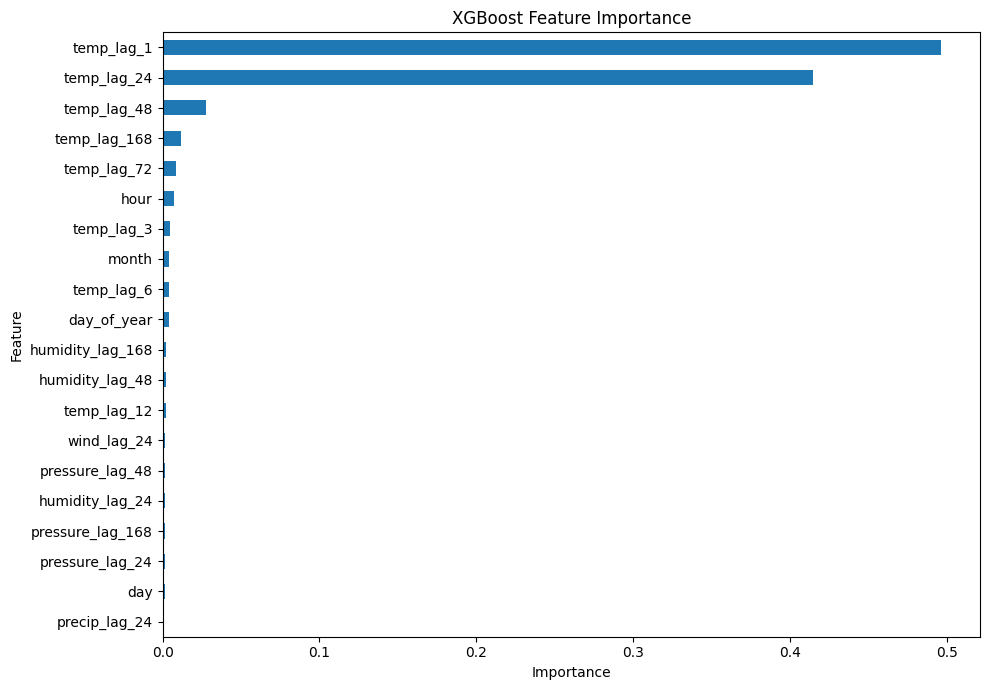

In [ ]:
import matplotlib.pyplot as plt

importance.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Variables the LSTM will look at
lstm_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m"
]

data = df[lstm_features].values

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data)

In [ ]:
sequence_length = 24

X = []
y = []

for i in range(sequence_length, len(scaled_data) - 24):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i+24, 0])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (87408, 24, 5)
y shape: (87408,)


In [ ]:
train_df = df[df["time"] < "2024-01-01"].copy()
test_df = df[df["time"] >= "2024-01-01"].copy()

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (78696, 28)
Test: (8760, 28)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

lstm_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m"
]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_df[lstm_features])
test_scaled = scaler.transform(test_df[lstm_features])

In [ ]:
sequence_length = 24

X_train = []
y_train = []

for i in range(sequence_length, len(train_scaled) - 24):
    X_train.append(train_scaled[i-sequence_length:i])
    y_train.append(train_scaled[i+24, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (78648, 24, 5)
y_train: (78648,)


In [ ]:
X_test_lstm = []
y_test_lstm = []

for i in range(sequence_length, len(test_scaled) - 24):
    X_test_lstm.append(test_scaled[i-sequence_length:i])
    y_test_lstm.append(test_scaled[i+24, 0])

X_test_lstm = np.array(X_test_lstm)
y_test_lstm = np.array(y_test_lstm)

print("X_test:", X_test_lstm.shape)
print("y_test:", y_test_lstm.shape)

X_test: (8712, 24, 5)
y_test: (8712,)


In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_test_lstm.shape)
print(y_test_lstm.shape)

(78648, 24, 5)
(78648,)
(8712, 24, 5)
(8712,)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

lstm_model = Sequential([
    LSTM(64, input_shape=(24, 5)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,033 (78.25 KB)

 Trainable params: 20,033 (78.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=False
)

Epoch 1/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - loss: 0.0052 - mae: 0.0555 - val_loss: 0.0710 - val_mae: 0.2430
Epoch 2/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - loss: 0.0042 - mae: 0.0503 - val_loss: 0.0520 - val_mae: 0.2029
Epoch 3/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - loss: 0.0050 - mae: 0.0543 - val_loss: 0.0505 - val_mae: 0.2000
Epoch 4/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - loss: 0.0044 - mae: 0.0510 - val_loss: 0.0570 - val_mae: 0.2182
Epoch 5/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - loss: 0.0051 - mae: 0.0549 - val_loss: 0.0613 - val_mae: 0.2254
Epoch 6/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 0.0049 - mae: 0.0538 - val_loss: 0.0456 - val_mae: 0.1955
Epoch 7/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.0043 - mae: 0.0509 - val_loss: 0.0379 - val_mae: 0.1767
Epoch 8/10
1106/1106 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - loss: 0.0037 - mae: 0.0473 - val_loss: 0.0334 - val_mae: 0.1648
Epoch 9/10
1106/1106 ━━━

In [ ]:
lstm_predictions_scaled = lstm_model.predict(X_test_lstm)

273/273 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
import numpy as np

dummy = np.zeros((len(lstm_predictions_scaled), 5))
dummy[:, 0] = lstm_predictions_scaled[:, 0]

lstm_predictions = scaler.inverse_transform(dummy)[:, 0]

In [ ]:
dummy_actual = np.zeros((len(y_test_lstm), 5))
dummy_actual[:, 0] = y_test_lstm

lstm_actual = scaler.inverse_transform(dummy_actual)[:, 0]

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

lstm_mae = mean_absolute_error(
    lstm_actual,
    lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        lstm_actual,
        lstm_predictions
    )
)

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)

LSTM MAE: 4.858605060060708
LSTM RMSE: 5.584374051966194


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Improved Random Forest",
        "XGBoost",
        "LSTM"
    ],
    "MAE": [
        1.127574,
        mae2,
        xgb_mae,
        lstm_mae
    ],
    "RMSE": [
        1.510273,
        rmse2,
        xgb_rmse,
        lstm_rmse
    ]
})

display(results.sort_values("MAE"))

,Model,MAE,RMSE
2,XGBoost,1.108561,1.477226
1,Improved Random Forest,1.116307,1.491564
0,Random Forest,1.127574,1.510273
3,LSTM,4.858605,5.584374


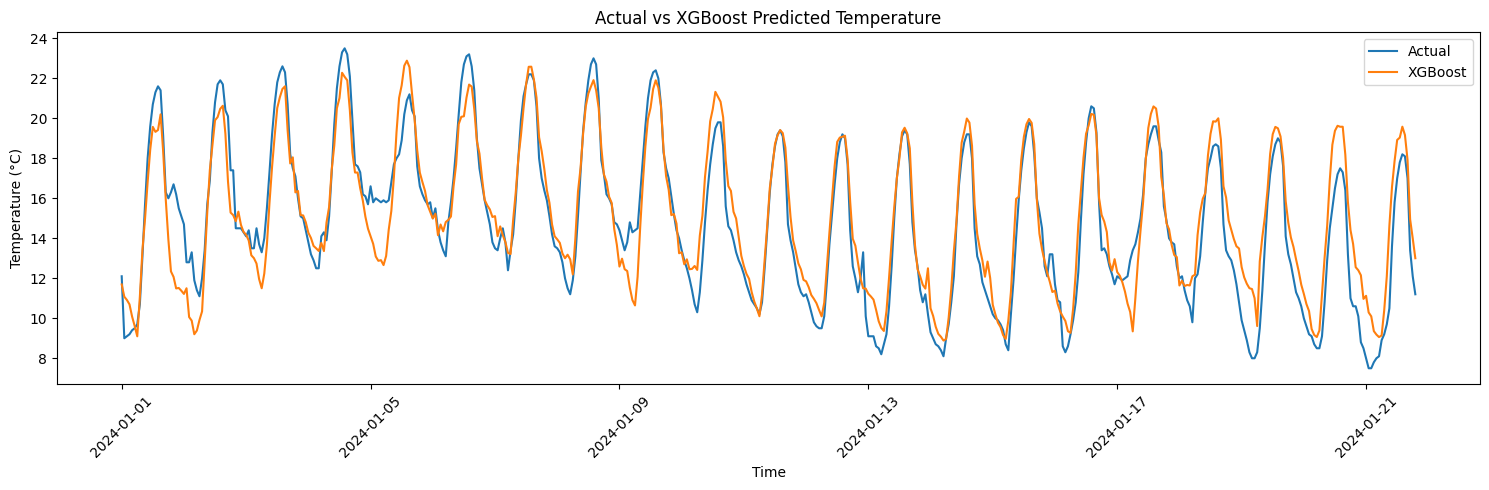

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    test["time"].iloc[:500],
    y_test.iloc[:500],
    label="Actual"
)

plt.plot(
    test["time"].iloc[:500],
    xgb_predictions[:500],
    label="XGBoost"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs XGBoost Predicted Temperature")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
baseline_predictions = test["temperature_2m"].shift(24)

baseline_predictions = baseline_predictions.iloc[24:].values
baseline_actual = test["target_temperature"].iloc[24:].values

baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline_actual,
        baseline_predictions
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 1.4644803113553113
Baseline RMSE: 1.9728262136414272


In [ ]:
improvement = (
    (baseline_mae - xgb_mae)
    / baseline_mae
) * 100

print(f"Improvement over baseline: {improvement:.2f}%")

Improvement over baseline: 24.30%


In [ ]:
import joblib

joblib.dump(xgb_model, "weather_xgboost_model.pkl")

['weather_xgboost_model.pkl']

In [ ]:
joblib.dump(features, "weather_features.pkl")

['weather_features.pkl']

In [ ]:
from google.colab import files

files.download("weather_xgboost_model.pkl")
files.download("weather_features.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
latest_24 = df.tail(24).copy()

In [ ]:
def prepare_prediction_features(df):

    latest = df.iloc[-1].copy()

    prediction_data = {
        "hour": latest["hour"],
        "day": latest["day"],
        "month": latest["month"],
        "day_of_year": latest["day_of_year"],

        "temp_lag_1": df["temperature_2m"].iloc[-1],
        "temp_lag_3": df["temperature_2m"].iloc[-3],
        "temp_lag_6": df["temperature_2m"].iloc[-6],
        "temp_lag_12": df["temperature_2m"].iloc[-12],
        "temp_lag_24": df["temperature_2m"].iloc[-24],
        "temp_lag_48": df["temperature_2m"].iloc[-48],
        "temp_lag_72": df["temperature_2m"].iloc[-72],
        "temp_lag_168": df["temperature_2m"].iloc[-168],

        "humidity_lag_24": df["relative_humidity_2m"].iloc[-24],
        "humidity_lag_48": df["relative_humidity_2m"].iloc[-48],
        "humidity_lag_168": df["relative_humidity_2m"].iloc[-168],

        "precip_lag_24": df["precipitation"].iloc[-24],

        "pressure_lag_24": df["pressure_msl"].iloc[-24],
        "pressure_lag_48": df["pressure_msl"].iloc[-48],
        "pressure_lag_168": df["pressure_msl"].iloc[-168],

        "wind_lag_24": df["wind_speed_10m"].iloc[-24]
    }

    return pd.DataFrame([prediction_data])

In [ ]:
X_future = prepare_prediction_features(df)

future_prediction = xgb_model.predict(X_future)

print("Predicted temperature 24 hours ahead:",
      future_prediction[0], "°C")

Predicted temperature 24 hours ahead: 14.45105 °C


In [ ]:
import requests
import json

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 25.6239,
    "longitude": 85.108696,
    "start_date": "2025-01-01",
    "end_date": "2026-08-23",
    "hourly": "temperature_2m,relative_humidity_2m,precipitation,pressure_msl,wind_speed_10m",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params)
data = response.json()

with open("patna_2025_2026.json", "w") as f:
    json.dump(data, f, indent=2)

print("Downloaded successfully!")

Downloaded successfully!


In [ ]:
import json
import pandas as pd

with open("patna_2025_2026.json", "r") as f:
    data_2025_2026 = json.load(f)

new_df = pd.DataFrame(data_2025_2026["hourly"])

new_df["time"] = pd.to_datetime(new_df["time"])

print(new_df.head())
print(new_df.shape)
print(new_df["time"].min())
print(new_df["time"].max())

                 time  temperature_2m  relative_humidity_2m  precipitation  \
0 2025-01-01 00:00:00            12.8                    92            0.0   
1 2025-01-01 01:00:00            12.4                    92            0.0   
2 2025-01-01 02:00:00            12.0                    93            0.0   
3 2025-01-01 03:00:00            11.6                    94            0.0   
4 2025-01-01 04:00:00            11.3                    93            0.0   

   pressure_msl  wind_speed_10m  
0        1018.0            10.6  
1        1017.4            10.2  
2        1016.7             9.9  
3        1016.4            10.3  
4        1016.6            10.4  
(14400, 6)
2025-01-01 00:00:00
2026-08-23 23:00:00


In [ ]:
print(new_df.isnull().sum())

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
dtype: int64


In [ ]:
import json
import pandas as pd

with open("patna_2025_2026.json", "r") as f:
    data_2025_2026 = json.load(f)

new_df = pd.DataFrame(data_2025_2026["hourly"])

new_df["time"] = pd.to_datetime(new_df["time"])

print(new_df.head())
print(new_df.shape)

                 time  temperature_2m  relative_humidity_2m  precipitation  \
0 2025-01-01 00:00:00            12.8                    92            0.0   
1 2025-01-01 01:00:00            12.4                    92            0.0   
2 2025-01-01 02:00:00            12.0                    93            0.0   
3 2025-01-01 03:00:00            11.6                    94            0.0   
4 2025-01-01 04:00:00            11.3                    93            0.0   

   pressure_msl  wind_speed_10m  
0        1018.0            10.6  
1        1017.4            10.2  
2        1016.7             9.9  
3        1016.4            10.3  
4        1016.6            10.4  
(14400, 6)


In [ ]:
print(new_df.isnull().sum())
print(new_df["time"].min())
print(new_df["time"].max())

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
pressure_msl            0
wind_speed_10m          0
dtype: int64
2025-01-01 00:00:00
2026-08-23 23:00:00


In [ ]:
new_df["hour"] = new_df["time"].dt.hour
new_df["day"] = new_df["time"].dt.day
new_df["month"] = new_df["time"].dt.month
new_df["day_of_year"] = new_df["time"].dt.dayofyear

new_df["temp_lag_1"] = new_df["temperature_2m"].shift(1)
new_df["temp_lag_3"] = new_df["temperature_2m"].shift(3)
new_df["temp_lag_6"] = new_df["temperature_2m"].shift(6)
new_df["temp_lag_12"] = new_df["temperature_2m"].shift(12)
new_df["temp_lag_24"] = new_df["temperature_2m"].shift(24)
new_df["temp_lag_48"] = new_df["temperature_2m"].shift(48)
new_df["temp_lag_72"] = new_df["temperature_2m"].shift(72)
new_df["temp_lag_168"] = new_df["temperature_2m"].shift(168)

new_df["humidity_lag_24"] = new_df["relative_humidity_2m"].shift(24)
new_df["humidity_lag_48"] = new_df["relative_humidity_2m"].shift(48)
new_df["humidity_lag_168"] = new_df["relative_humidity_2m"].shift(168)

new_df["precip_lag_24"] = new_df["precipitation"].shift(24)

new_df["pressure_lag_24"] = new_df["pressure_msl"].shift(24)
new_df["pressure_lag_48"] = new_df["pressure_msl"].shift(48)
new_df["pressure_lag_168"] = new_df["pressure_msl"].shift(168)

new_df["wind_lag_24"] = new_df["wind_speed_10m"].shift(24)

In [ ]:
new_df["target_temperature"] = new_df["temperature_2m"].shift(-24)

In [ ]:
new_df = new_df.dropna().reset_index(drop=True)

In [ ]:
xgb_model
X_new = new_df[features]

new_predictions = xgb_model.predict(X_new)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_new = new_df["target_temperature"]

new_mae = mean_absolute_error(y_new, new_predictions)
new_rmse = np.sqrt(mean_squared_error(y_new, new_predictions))

print("2025–2026 MAE:", new_mae)
print("2025–2026 RMSE:", new_rmse)

2025–2026 MAE: 1.1741443764519046
2025–2026 RMSE: 1.585390610665026


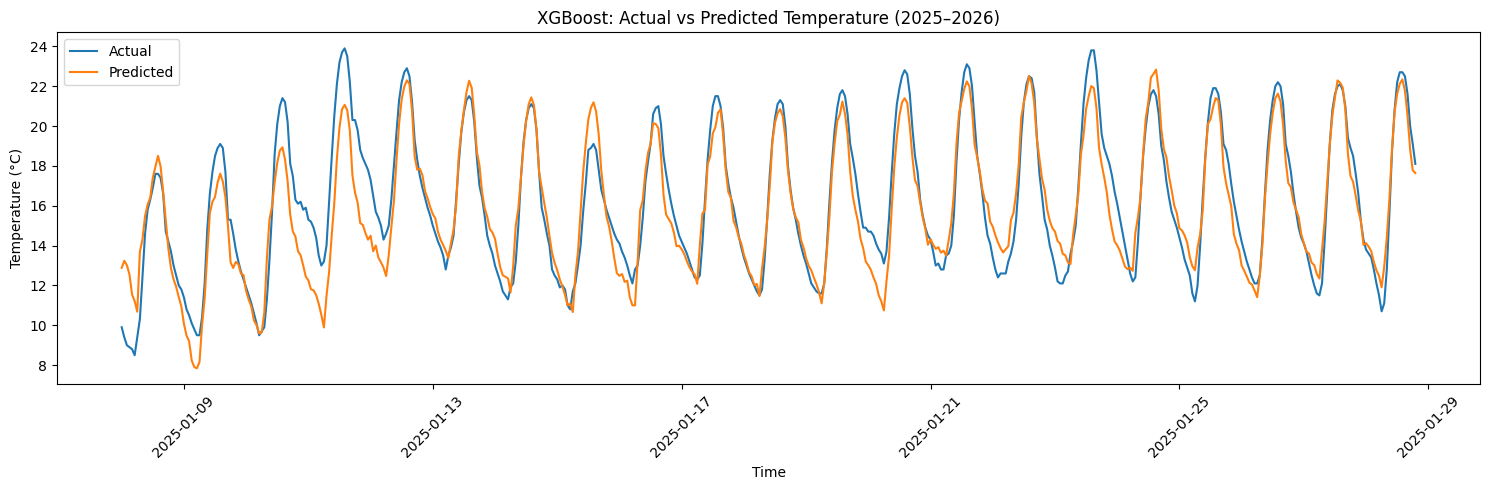

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    new_df["time"].iloc[:500],
    y_new.iloc[:500],
    label="Actual"
)

plt.plot(
    new_df["time"].iloc[:500],
    new_predictions[:500],
    label="Predicted"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("XGBoost: Actual vs Predicted Temperature (2025–2026)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "time": new_df["time"].iloc[:20],
    "actual_temperature": y_new.iloc[:20].values,
    "predicted_temperature": new_predictions[:20]
})

display(comparison)

,time,actual_temperature,predicted_temperature
0,2025-01-08 00:00:00,9.9,12.886445
1,2025-01-08 01:00:00,9.4,13.236816
2,2025-01-08 02:00:00,9.0,13.014507
3,2025-01-08 03:00:00,8.9,12.547905
4,2025-01-08 04:00:00,8.8,11.545403
5,2025-01-08 05:00:00,8.5,11.210811
6,2025-01-08 06:00:00,9.4,10.682729
7,2025-01-08 07:00:00,10.3,13.685192
8,2025-01-08 08:00:00,12.4,14.304559
9,2025-01-08 09:00:00,14.6,15.474229


In [ ]:
df["target_24h"] = df["temperature_2m"].shift(-24)

In [ ]:
forecast_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "pressure_msl",
    "wind_speed_10m",
    "hour",
    "day",
    "month",
    "day_of_year"
]

In [ ]:
train_forecast = df[df["time"] < "2024-01-01"].copy()
test_forecast = df[df["time"] >= "2024-01-01"].copy()

train_forecast = train_forecast.dropna(subset=["target_24h"])
test_forecast = test_forecast.dropna(subset=["target_24h"])

X_train_forecast = train_forecast[forecast_features]
y_train_forecast = train_forecast["target_24h"]

X_test_forecast = test_forecast[forecast_features]
y_test_forecast = test_forecast["target_24h"]

In [ ]:
from xgboost import XGBRegressor

forecast_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

forecast_model.fit(
    X_train_forecast,
    y_train_forecast
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

forecast_predictions = forecast_model.predict(X_test_forecast)

mae = mean_absolute_error(
    y_test_forecast,
    forecast_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_forecast,
        forecast_predictions
    )
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 1.0618255217651742
RMSE: 1.43614040433433


In [ ]:
latest_24 = new_df.tail(24).copy()

X_tomorrow = latest_24[forecast_features]

tomorrow_predictions = forecast_model.predict(X_tomorrow)

In [ ]:
tomorrow_times = pd.date_range(
    start="2026-08-24 00:00",
    periods=24,
    freq="h"
)

tomorrow_forecast = pd.DataFrame({
    "time": tomorrow_times,
    "predicted_temperature": tomorrow_predictions
})

display(tomorrow_forecast)

,time,predicted_temperature
0,2026-08-24 00:00:00,28.549906
1,2026-08-24 01:00:00,28.337502
2,2026-08-24 02:00:00,27.713264
3,2026-08-24 03:00:00,27.489323
4,2026-08-24 04:00:00,26.721140
5,2026-08-24 05:00:00,27.427555
6,2026-08-24 06:00:00,27.867496
7,2026-08-24 07:00:00,28.477266
8,2026-08-24 08:00:00,30.088259
9,2026-08-24 09:00:00,30.711800


In [ ]:
forecast_hours = range(8, 169, 8)

for h in forecast_hours:
    df[f"target_{h}h"] = df["temperature_2m"].shift(-h)

print(list(forecast_hours))

[8, 16, 24, 32, 40, 48, 56, 64, 72, 80, 88, 96, 104, 112, 120, 128, 136, 144, 152, 160, 168]


In [ ]:
features_7day = [
    "hour",
    "day",
    "month",
    "day_of_year",
    "temp_lag_1",
    "temp_lag_3",
    "temp_lag_6",
    "temp_lag_12",
    "temp_lag_24",
    "temp_lag_48",
    "temp_lag_72",
    "temp_lag_168",
    "humidity_lag_24",
    "humidity_lag_48",
    "humidity_lag_168",
    "precip_lag_24",
    "pressure_lag_24",
    "pressure_lag_48",
    "pressure_lag_168",
    "wind_lag_24"
]

print("Features:", len(features_7day))

Features: 20


In [ ]:
print(df[features_7day].head())

   hour  day  month  day_of_year  temp_lag_1  temp_lag_3  temp_lag_6  \
0     0    9      1            9        13.8        14.8        17.3   
1     1    9      1            9        13.7        14.2        16.3   
2     2    9      1            9        13.3        13.8        15.6   
3     3    9      1            9        13.0        13.7        14.8   
4     4    9      1            9        12.6        13.3        14.2   

   temp_lag_12  temp_lag_24  temp_lag_48  temp_lag_72  temp_lag_168  \
0         20.4         13.9         13.0         13.5          19.5   
1         20.8         14.0         12.6         13.3          19.5   
2         21.2         14.2         12.3         12.9          19.2   
3         21.2         14.0         12.4         12.5          18.7   
4         20.5         13.6         12.6         12.3          18.5   

   humidity_lag_24  humidity_lag_48  humidity_lag_168  precip_lag_24  \
0             91.0             93.0              75.0            0.0

In [ ]:
from xgboost import XGBRegressor

models_8h = {}

for h in forecast_hours:

    target = f"target_{h}h"

    train_data = df[
        (df["time"] < "2024-01-01") &
        (df[target].notna())
    ]

    X = train_data[features_7day]
    y = train_data[target]

    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X, y)

    models_8h[h] = model

    print(f"{h} hour model trained")

8 hour model trained
16 hour model trained
24 hour model trained
32 hour model trained
40 hour model trained
48 hour model trained
56 hour model trained
64 hour model trained
72 hour model trained
80 hour model trained
88 hour model trained
96 hour model trained
104 hour model trained
112 hour model trained
120 hour model trained


In [ ]:
latest_features = new_df[features_7day].iloc[[-1]]

print(latest_features)

In [ ]:
forecast_hours = list(range(8, 169, 8))

predictions = []

for h in forecast_hours:
    prediction = models_8h[h].predict(latest_features)[0]
    predictions.append(prediction)

print(predictions)

In [ ]:
last_time = new_df["time"].iloc[-1]

forecast_times = [
    last_time + pd.Timedelta(hours=h)
    for h in forecast_hours
]

forecast_7day = pd.DataFrame({
    "Hours_Ahead": forecast_hours,
    "Time": forecast_times,
    "Predicted_Temperature_C": predictions
})

display(forecast_7day)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    forecast_7day["Time"],
    forecast_7day["Predicted_Temperature_C"],
    marker="o"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("7-Day Temperature Forecast")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or ‘Colaboratory’, allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a <strong>student</strong>, a <strong>data scientist</strong> or an <strong>AI researcher</strong>, Colab can make your work easier. Watch <a href="https://www.youtube.com/watch?v=inN8seMm7UI">Introduction to Colab</a> or <a href="https://www.youtube.com/watch?v=rNgswRZ2C1Y">Colab features you may have missed</a> to learn more or just get started below!

<div class="markdown-google-sans">

## <strong>Getting started</strong>
</div>

The document that you are reading is not a static web page, but an interactive environment called a <strong>Colab notebook</strong> that lets you write and execute code.

For example, here is a <strong>code cell</strong> with a short Python script that computes a value, stores it in a variable and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut 'Command/Ctrl+Enter'. To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

Colab notebooks allow you to combine <strong>executable code</strong> and <strong>rich text</strong> in a single document, along with <strong>images</strong>, <strong>HTML</strong>, <strong>LaTeX</strong> and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To find out more, see <a href="/notebooks/basic_features_overview.ipynb">Overview of Colab</a>. To create a new Colab notebook you can use the File menu above, or use the following link: <a href="http://colab.research.google.com#create=true">Create a new Colab notebook</a>.

Colab notebooks are Jupyter notebooks that are hosted by Colab. To find out more about the Jupyter project, see <a href="https://www.jupyter.org">jupyter.org</a>.

## Google Colab is available in VS Code!
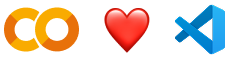

Try the new <a href="https://marketplace.visualstudio.com/items?itemName=Google.colab">Google Colab extension</a> for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the <strong><em>Extensions</em></strong> view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any <code>.ipynb</code> notebook file in your local workspace and either running a cell or clicking the <strong><em>Select kernel</em></strong> button in the top right.
*  Click <strong><em>Colab</em></strong> and then select your desired runtime, sign in with your Google Account and you're all set!

See more details in our <a href="https://developers.googleblog.com/google-colab-is-coming-to-vs-code">announcement blog here</a>.

## Access popular AI models via Google Colab-AI without an API key
All users have access to most popular LLMs via the <code>google-colab-ai</code> Python library, and paid users have access to a wider selection of models. For more details, refer to <a href="https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb">getting started with Google Colab AI</a>.



In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Explore the Gemini API
The Gemini API gives you access to Gemini models created by Google DeepMind. Gemini models are built from the ground up to be multimodal, so you can reason seamlessly across text, images, code and audio.

**How to get started**
*  Go to <a href="https://aistudio.google.com/">Google AI Studio</a> and log in with your Google Account.
*  <a href="https://aistudio.google.com/app/apikey">Create an API key</a>.
* Use a quickstart for <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb">Python</a> or call the REST API using <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb">curl</a>.

**Discover Gemini's advanced capabilities**
*  Play with Gemini <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb">multimodal outputs</a>, mixing text and images in an iterative way.
*  Discover the <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb">multimodal Live API</a> &#40;demo <a href="https://aistudio.google.com/live">here</a>&#41;.
*  Learn how to <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb&quot;">analyse images and detect items in your pictures</a> using Gemini &#40;bonus, there's a <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb">3D version</a> as well!&#41;.
*  Unlock the power of the <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb">Gemini thinking model</a>, capable of solving complex tasks with its inner thoughts.
      
**Explore complex use cases**
*  Use <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb">Gemini grounding capabilities</a> to create a report on a company based on what the model can find on the Internet.
*  Extract <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb">invoices and form data from PDFs</a> in a structured way.
*  Create <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb">illustrations based on a whole book</a> using Gemini large context window and Imagen.

To learn more, take a look at the <a href="https://github.com/google-gemini/cookbook">Gemini cookbook</a> or visit the <a href="https://ai.google.dev/docs/">Gemini API documentation</a>.


Colab now has AI features powered by <a href="https://gemini.google.com">Gemini</a>. The video below provides information on how to use these features, whether you're new to Python or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  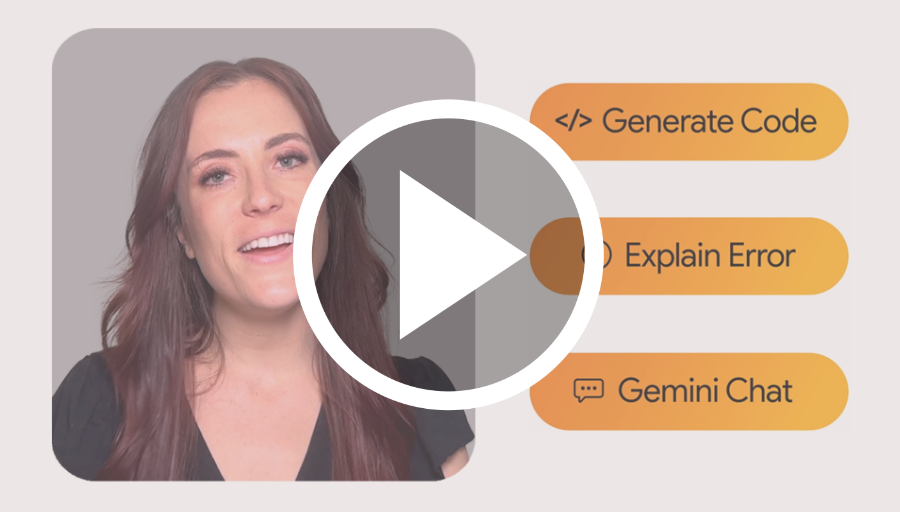
  </a>
</center>

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyse and visualise data. The code cell below uses <strong>numpy</strong> to generate some random data, and uses <strong>matplotlib</strong> to visualise it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from GitHub and many other sources. To find out more about importing data, and how Colab can be used for data science, see the links below under <a href="#working-with-data">Working with data</a>.

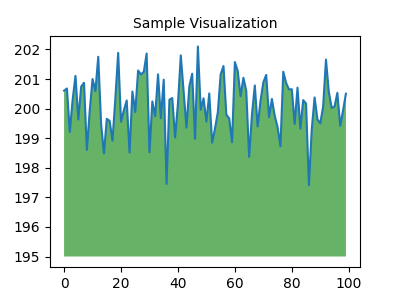

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Colab notebooks execute code on Google's cloud servers, meaning that you can leverage the power of Google hardware, including <a href="#using-accelerated-hardware">GPUs and TPUs</a>, regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for <strong>pandas</strong> code to finish running and want to go faster, you can switch to a GPU runtime and use libraries like <a href="https://rapids.ai/cudf-pandas">RAPIDS cuDF</a> that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb">10-minute guide</a> or
 <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb">US stock market data analysis demo</a>.

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it and evaluate the model, all in just <a href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb">a few lines of code</a>.

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the <a href="#machine-learning-examples">machine learning examples</a> below.

<div class="markdown-google-sans">

## More resources

### Working with notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with data
</div>

- [Loading data: Drive, Sheets and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualising data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine learning

<div>

These are a few of the notebooks related to machine learning, including Google's online machine learning course. See the <a href="https://developers.google.com/machine-learning/crash-course/">full course website</a> for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using accelerated hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer &#40;ViT&#41; for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- <a href="https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html">Train a miniGPT language model with JAX AI stack</a>
- <a href="https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb">LoRA/QLoRA finetuning for LLM using Tunix</a>
- <a href="https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/">Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA</a>
- <a href="https://keras.io/keras_hub/guides/hugging_face_keras_integration/">Loading Hugging Face transformers checkpoints</a>
- <a href="https://keras.io/guides/int8_quantization_in_keras/">8-bit integer quantisation in Keras</a>
- <a href="https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/">Float8 training and inference with a simple transformer model</a>
- <a href="https://keras.io/keras_hub/guides/transformer_pretraining/">Pretraining a transformer from scratch with KerasHub</a>
- <a href="https://keras.io/examples/vision/mnist_convnet/">Simple MNIST convnet</a>
- <a href="https://keras.io/examples/vision/image_classification_from_scratch/">Image classification from scratch using Keras 3</a>
- <a href="https://keras.io/keras_hub/guides/classification_with_keras_hub/">Image classification with KerasHub</a>
